[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_connect/BA_L7_connect.ipynb)

# BA_L7_connect: Rolling connectedness: mean correlation and absorption ratio

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Mean pairwise correlation and absorption ratio (share of variance of the first principal component) of 19 cryptocurrencies, on rolling 90-day windows of daily log returns moved forward 5 days at a time (EODHD, January 2021 - October 2026).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Data

Daily closes of 19 coins from EODHD (course repository, `data/market`), 1 January 2021 to 23 October 2026.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [5]:
COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()           # daily log returns in %
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


### Method

On every 90-day window (moved forward 5 days at a time) the cell computes the mean pairwise correlation of the 19 coins and the
**absorption ratio** (AR)

$$ \mathrm{AR}_t = \frac{\lambda_1}{\sum_{k=1}^N \lambda_k} = \frac{\lambda_1}{N}, $$

where $\lambda_1 \ge \lambda_2 \ge \dots$ are the eigenvalues of the window's correlation matrix (the variances of its principal components).
AR lies between $1/N$ and 1. With all pairwise correlations equal to $\rho$, $\lambda_1 = 1 + (N-1)\rho$: for $N = 19$ and $\rho = 0.60$,
$\mathrm{AR} = 11.8/19 = 0.62$. A high AR means one common factor drives most coins, so diversification across coins is weak.

In [6]:
W = 90
iu = np.triu_indices(len(COINS), 1)
mc, ar = {}, {}
for k in range(W, len(R) + 1, 5):
    x = R.iloc[k - W:k]
    c = x.corr().values
    mc[x.index[-1]] = c[iu].mean()
    ev = np.linalg.eigvalsh(c)[::-1]
    ar[x.index[-1]] = ev[0] / ev.sum()
mc, ar = pd.Series(mc), pd.Series(ar)
print(pd.DataFrame({
    'value': [mc.min(), mc.max(), mc.iloc[-1], ar.mean(), ar.iloc[-1]],
    'window ending': [mc.idxmin().date(), mc.idxmax().date(), mc.index[-1].date(), 'all windows', ar.index[-1].date()]},
    index=['mean pairwise correlation, lowest', 'mean pairwise correlation, highest', 'mean pairwise correlation, last window',
           'absorption ratio, average', 'absorption ratio, last window']).round(3).to_string())

                                        value window ending
mean pairwise correlation, lowest       0.363    2021-04-21
mean pairwise correlation, highest      0.854    2021-08-14
mean pairwise correlation, last window  0.535    2026-10-22
absorption ratio, average               0.682   all windows
absorption ratio, last window           0.589    2026-10-22


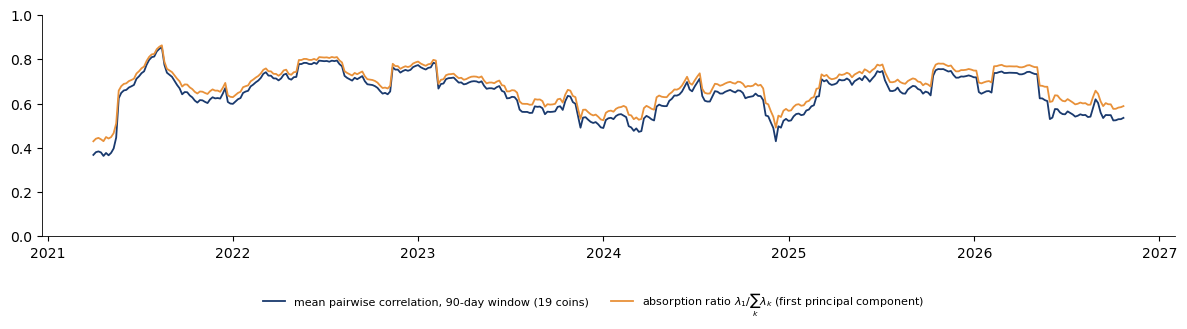

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.3))
ax.plot(mc.index, mc, color=BLUE, lw=1.3, label='mean pairwise correlation, 90-day window (19 coins)')
ax.plot(ar.index, ar, color=BTC, lw=1.3, label=r'absorption ratio $\lambda_1 / \sum_k \lambda_k$ (first principal component)')
ax.set_ylim(0, 1)
slide_fig(fig, 'ba_l7_connect', 0.15, ncol=2)